# Steam Game Analysis

**Name:** XUN WU

This notebook explores how game attributes relate to review activity. Total reviews represent discussion volume, while positive review rate describes reviewer sentiment.

### Research Background

This project is inspired by **Predicting the Popularity of Games on Steam** by De Luisa et al. (2021).

The paper uses first-month player activity and game attributes to predict second-month player activity. We draw on its data preparation and feature analysis methods to explore review activity using a different public dataset.

| Item | Description |
|---|---|
| Research paper | De Luisa et al. (2021), **Predicting the Popularity of Games on Steam**. **Elektrotehniški vestnik**, 88(4), 151–162. [Full text](https://ev.fe.uni-lj.si/4-2021/Luisa.pdf) |
| Dataset | [FronkonGames/steam-games-dataset](https://huggingface.co/datasets/FronkonGames/steam-games-dataset), compiled from Steam and SteamSpy |
| Source documentation | [Dataset card](https://huggingface.co/datasets/FronkonGames/steam-games-dataset/blob/main/README.md) · [Collection code and documentation](https://github.com/FronkonGames/Steam-Games-Scraper) |
| File | `games.csv` |
| File size | 401.1 MB |
| Original data | 125,855 records; 40 fields after correcting the CSV header |
| Selected data | 32,387 records, covering releases from 2020–2025 with at least 10 reviews |
| Dataset revision | `52ba62abfa707a2fa31f4d147c2777a9d9fbd2da` |


## 1. Environment and project paths

Select the project `.venv` as the notebook kernel in VS Code. Run cells in order. Paths below support starting this notebook from the project root or its `code` folder.


In [58]:
from pathlib import Path

# Locate the project without using machine-specific absolute paths.
working_directory = Path.cwd().resolve()
project_root = next(
    (folder for folder in (working_directory, *working_directory.parents)
     if folder.name == "Steam Game Analysis"
     and (folder / "requirements.txt").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from the Steam Game Analysis project folder.")

DATA_DIR = project_root / "data"
DOCS_DIR = project_root / "docs"
IMAGES_DIR = project_root / "resources" / "images"
CHARTS_DIR = project_root / "resources" / "charts"

print(f"Project folder: {project_root}")


Project folder: /Users/xunxun/Documents/Projects/DSAI/Semester_1/CP388001_Python/04_Project/Final Project/Steam Game Analysis


## 2. Download Data

Download a fixed version of the Steam CSV dataset from Hugging Face to the local `data/` folder.


In [59]:
from huggingface_hub import hf_hub_download

# Pin the CSV revision so repeated runs use the same source data.
DATASET_ID = "FronkonGames/steam-games-dataset"
DATASET_REVISION = "52ba62abfa707a2fa31f4d147c2777a9d9fbd2da"
CSV_PATH = DATA_DIR / "games.csv"

DATA_DIR.mkdir(parents=True, exist_ok=True)

if CSV_PATH.is_file() and CSV_PATH.stat().st_size > 0:
    print(f"Using local file: {CSV_PATH}")
else:
    # Download only games.csv; Hugging Face manages the transfer and cache.
    downloaded_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename="games.csv",
        revision=DATASET_REVISION,
        local_dir=DATA_DIR,
        token=False,  # Download without using the saved token.
    )
    print(f"Downloaded: {downloaded_path}")

print(f"Dataset revision: {DATASET_REVISION}")
print(f"File size: {CSV_PATH.stat().st_size / 1_000_000:.1f} MB")


Using local file: /Users/xunxun/Documents/Projects/DSAI/Semester_1/CP388001_Python/04_Project/Final Project/Steam Game Analysis/data/games.csv
Dataset revision: 52ba62abfa707a2fa31f4d147c2777a9d9fbd2da
File size: 401.1 MB


## 3. Data Loading and Inspection

Load the dataset and inspect its structure and available fields.


In [60]:
import pandas as pd

# Read the local CSV without guessing mixed column types in chunks.
df = pd.read_csv(CSV_PATH, low_memory=False)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())

print(df.head())
df.info()

Rows: 125,855
Columns: 39

Column names:
['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'DiscountDLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']
                                         AppID          Name Release date  \
2539430             Black Dragon Mage Playtest   Aug 1, 2023        0 - 0   
496350   Supipara - Chapter 1 Spring Has Come!  Jul 29, 2016    0 - 20000   
1034400      Mystery Solitaire The Black Raven   May 6, 2019    0 - 20000   
3292190            버튜버 파라노이아 - Vtuber Parano

### Check CSV Structure

Compare the header and row lengths to identify possible column misalignment.

In [61]:
import csv

# Inspect the original CSV before making corrections.
with CSV_PATH.open("r", encoding="utf-8-sig", newline="") as file:
    reader = csv.reader(file)
    header = next(reader)
    first_row = next(reader)

print(f"Header fields: {len(header)}")
print(f"Row fields: {len(first_row)}")

# Compare the first fields by position.
for i in range(12):
    column = header[i] if i < len(header) else "(no header)"
    print(f"{i:2}: {column:<22} | {first_row[i]}")

Header fields: 39
Row fields: 40
 0: AppID                  | 2539430
 1: Name                   | Black Dragon Mage Playtest
 2: Release date           | Aug 1, 2023
 3: Estimated owners       | 0 - 0
 4: Peak CCU               | 0
 5: Required age           | 0
 6: Price                  | 0.0
 7: DiscountDLC count      | 0
 8: About the game         | 0
 9: Supported languages    | 
10: Full audio languages   | []
11: Reviews                | []


### Correct CSV Header

Separate the merged Discount and DLC count headers, then reload the data.

In [62]:
# Restore the two separate column names.
corrected_header = []
for column in header:
    if column == "DiscountDLC count":
        corrected_header.extend(["Discount", "DLC count"])
    else:
        corrected_header.append(column)

# Replace the header during loading; leave the source file unchanged.
df = pd.read_csv(
    CSV_PATH,
    header=0,
    names=corrected_header,
    index_col=False,
    low_memory=False,
)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print(df.iloc[:5, :10])
df.info()

Rows: 125,855
Columns: 40
     AppID                                   Name  Release date  \
0  2539430             Black Dragon Mage Playtest   Aug 1, 2023   
1   496350  Supipara - Chapter 1 Spring Has Come!  Jul 29, 2016   
2  1034400      Mystery Solitaire The Black Raven   May 6, 2019   
3  3292190            버튜버 파라노이아 - Vtuber Paranoia  Oct 31, 2024   
4  3631080                          Maze Quest VR  Apr 24, 2025   

  Estimated owners  Peak CCU  Required age  Price  Discount  DLC count  \
0            0 - 0         0             0   0.00         0          0   
1        0 - 20000         0             0   5.24        65          0   
2        0 - 20000         0             0   4.99         0          0   
3        0 - 20000         1             0   8.99         0          1   
4        0 - 20000         0             0   4.99         0          0   

                                      About the game  
0                                                NaN  
1  Springtime, A

## 4. Data Selection and Quality Check

Select relevant fields and check missing values, duplicate IDs, and release dates.

In [63]:
columns = [
    "AppID", "Name", "Release date", "Price", "Discount",
    "Estimated owners", "Peak CCU", "Positive", "Negative",
    "Supported languages", "Genres", "Categories",
    "Average playtime forever", "Median playtime forever",
]

# Keep the original DataFrame for reference.
games = df[columns].copy()

print(
    games.isna().sum()
    .rename("Missing values")
    .to_frame()
)

print(f"Duplicate AppIDs: {games['AppID'].duplicated().sum():,}")

# Preserve the original dates while checking conversion.
release_dates = pd.to_datetime(
    games["Release date"],
    format="%b %d, %Y",
    errors="coerce",
)

print(f"Unparsed dates: {release_dates.isna().sum():,}")
print(f"Earliest release: {release_dates.min()}")
print(f"Latest release: {release_dates.max()}")

print(
    games.loc[
        release_dates.isna(),
        ["AppID", "Name", "Release date"],
    ].head(10)
)

                          Missing values
AppID                                  0
Name                                   1
Release date                           0
Price                                  0
Discount                               0
Estimated owners                       0
Peak CCU                               0
Positive                               0
Negative                               0
Supported languages                    0
Genres                              8423
Categories                          8966
Average playtime forever               0
Median playtime forever                0
Duplicate AppIDs: 0
Unparsed dates: 0
Earliest release: 1997-06-30 00:00:00
Latest release: 2026-12-01 00:00:00
Empty DataFrame
Columns: [AppID, Name, Release date]
Index: []


### Select the Study Period

Keep games released from 2020 to 2025 and summarize their release years.

In [64]:
# Convert dates and retain games within the study period.
games["Release date"] = release_dates

study = games.loc[
    games["Release date"].between("2020-01-01", "2025-12-31")
].copy()

study["Release year"] = study["Release date"].dt.year

print(f"Original records: {len(games):,}")
print(f"Selected records: {len(study):,}")
print(f"Excluded records: {len(games) - len(study):,}")

print(
    study.groupby("Release year")
    .size()
    .rename("Games")
    .to_frame()
)

print(
    study[["Name", "Genres", "Categories"]]
    .isna()
    .sum()
    .rename("Missing values")
    .to_frame()
)

Original records: 125,855
Selected records: 91,763
Excluded records: 34,092
              Games
Release year       
2020           8804
2021          11067
2022          12288
2023          14598
2024          20033
2025          24973
            Missing values
Name                     0
Genres                8343
Categories            8608


## 5. Data Transformation

Convert language, genre, and category fields into lists for analysis.


In [65]:
def split_items(value, is_language=False):
    if pd.isna(value):
        return []

    text = value.strip()

    if is_language:
        text = text.removeprefix("[").removesuffix("]")

    items = []
    for item in text.split(","):
        item = item.strip()

        # Remove surrounding quotes, keeping apostrophes inside names.
        if is_language:
            item = item.strip("'\"")

        if item:
            items.append(item)

    return items


study["Language list"] = study["Supported languages"].apply(
    lambda value: split_items(value, is_language=True)
)
study["Language count"] = study["Language list"].str.len()

study["Genre list"] = study["Genres"].apply(split_items)
study["Category list"] = study["Categories"].apply(split_items)

print(
    study[
        ["Name", "Language list", "Language count",
         "Genre list", "Category list"]
    ].head().to_string(index=False)
)

                       Name                                                                                        Language list  Language count                  Genre list                                                        Category list
 Black Dragon Mage Playtest                                                                                                   []               0                          []                                                                   []
버튜버 파라노이아 - Vtuber Paranoia                                                                                             [Korean]               1 [Casual, Indie, Simulation]                  [Single-player, Steam Achievements, Family Sharing]
              Maze Quest VR                                                                                            [English]               1      [Action, Early Access]         [Single-player, VR Only, Steam Leaderboards, Family Sharing]
                   Agony VR [Eng

### Review Metrics

Calculate total reviews and positive review rates.

In [66]:
study["Total reviews"] = study["Positive"] + study["Negative"]

# Calculate rates only for games with reviews.
study["Positive rate"] = (
    study["Positive"]
    / study["Total reviews"].replace(0, float("nan"))
    * 100
)

print(
    study[
        ["Name", "Positive", "Negative",
         "Total reviews", "Positive rate"]
    ].head().to_string(index=False)
)

print(f"Games without reviews: {(study['Total reviews'] == 0).sum():,}")

                       Name  Positive  Negative  Total reviews  Positive rate
 Black Dragon Mage Playtest         0         0              0            NaN
버튜버 파라노이아 - Vtuber Paranoia         0         0              0            NaN
              Maze Quest VR         0         0              0            NaN
                   Agony VR         0         0              0            NaN
         Armored Brigade II       117        13            130           90.0
Games without reviews: 38,529


### Filter Games by Review Count

Keep games with at least 10 reviews for subsequent analysis.

In [67]:
before_filter = len(study)

# Use 10 reviews as the minimum threshold.
study = study.loc[study["Total reviews"] >= 10].copy()

print(f"Before filtering: {before_filter:,}")
print(f"Excluded: {before_filter - len(study):,}")
print(f"Remaining: {len(study):,}")

Before filtering: 91,763
Excluded: 59,376
Remaining: 32,387


### Numerical Summary

Inspect numerical ranges and the coverage of activity data.


In [68]:
numeric_columns = [
    "Price", "Discount", "Positive", "Negative", "Total reviews",
    "Positive rate", "Language count", "Peak CCU",
    "Average playtime forever",
]

print(study[numeric_columns].describe().round(2).to_string())
print("\nNegative values:")
print((study[numeric_columns] < 0).sum().to_string())

# A recorded zero does not necessarily mean that nobody played the game.
print("\nActivity data coverage:")
for column in ["Average playtime forever", "Peak CCU"]:
    zero_count = (study[column] == 0).sum()
    zero_percent = zero_count / len(study) * 100
    print(f"{column}: {zero_count:,} zeros ({zero_percent:.1f}%)")


          Price  Discount    Positive   Negative  Total reviews  Positive rate  Language count   Peak CCU  Average playtime forever
count  32387.00  32387.00    32387.00   32387.00       32387.00       32387.00        32387.00   32387.00                  32387.00
mean       5.98     27.40     1372.19     245.12        1617.31          80.71            5.87      78.98                    281.60
std       12.28     30.97    16197.82    3692.21       18786.77          16.61           11.06    1728.09                   3778.44
min        0.00      0.00        0.00       0.00          10.00           0.00            0.00       0.00                      0.00
25%        1.00      0.00       15.00       2.00          19.00          71.97            1.00       0.00                      0.00
50%        3.49     10.00       35.00       8.00          43.00          84.62            2.00       0.00                      0.00
75%        7.49     50.00      149.00      30.00         185.00          93.

## 6. Data Aggregation

Summarize review counts and positive rates by release year.


In [69]:
year_summary = study.groupby("Release year").agg(
    Games=("AppID", "count"),
    Median_reviews=("Total reviews", "median"),
    Mean_reviews=("Total reviews", "mean"),
    Median_positive_rate=("Positive rate", "median"),
)

print(year_summary.round(2).to_string())

              Games  Median_reviews  Mean_reviews  Median_positive_rate
Release year                                                           
2020           5579            48.0       2424.96                 81.48
2021           5607            41.0       1575.15                 82.54
2022           5444            39.0       1571.93                 83.33
2023           5712            44.0       1426.18                 85.19
2024           6889            43.0       1457.52                 87.50
2025           3156            46.0       1037.51                 89.85


### Key points
After applying the 10-review threshold, annual median review counts range from 39 to 48. Mean counts remain much higher, indicating a skewed distribution. Median positive rates increase across release years, but this comparison includes only games meeting the review threshold.

## 7. Visualizations

Explore game counts, review distributions, and price relationships.

### Games by Release Year

Compare game counts across release years.

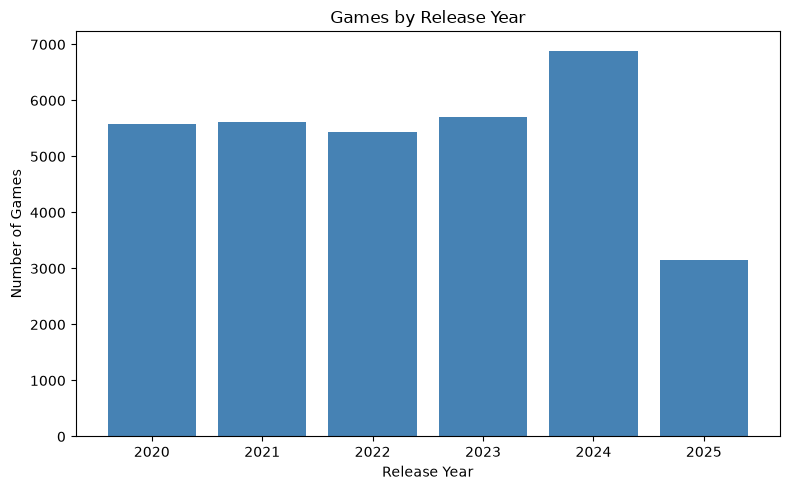

In [70]:
import matplotlib.pyplot as plt

games_by_year = study.groupby("Release year").size()

plt.figure(figsize=(8, 5))
plt.bar(games_by_year.index, games_by_year.values, color="steelblue")

plt.title("Games by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Games")
plt.xticks(games_by_year.index)
plt.tight_layout()

# Save the updated chart.
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(CHARTS_DIR / "games_by_release_year.png", dpi=150)
plt.show()

### Key Points
In the selected sample, 2024 has the highest count (6,889), while 2025 has the lowest (3,156). These counts describe the filtered sample rather than all Steam releases. Differences may reflect dataset coverage and time available to accumulate reviews.

### Distribution of Review Counts

Show the distribution of log-transformed review counts.

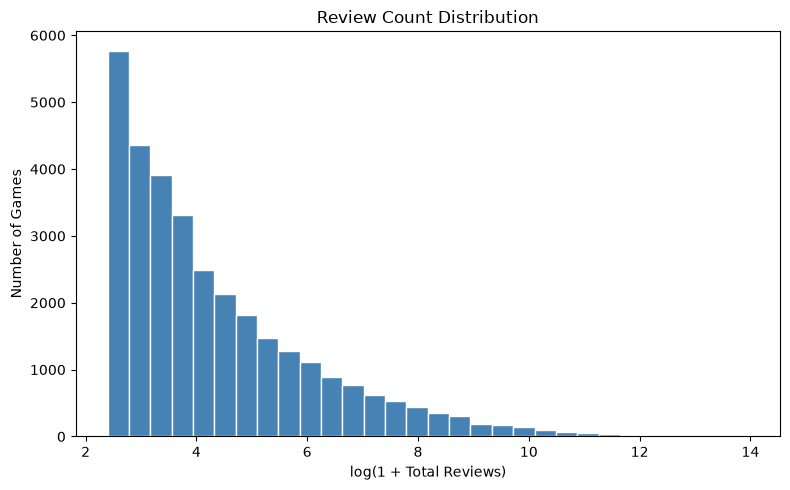

In [71]:
import numpy as np

log_reviews = np.log1p(study["Total reviews"])

plt.figure(figsize=(8, 5))
plt.hist(log_reviews, bins=30, color="steelblue", edgecolor="white")

plt.title("Review Count Distribution")
plt.xlabel("log(1 + Total Reviews)")
plt.ylabel("Number of Games")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "review_count_distribution.png", dpi=150)
plt.show()

### Key points
Review counts remain strongly right-skewed. Most games have relatively few reviews, while a small number have much higher counts. This explains why mean review counts exceed medians.

### Price and Review Activity

Compare prices and review counts using log transformations.

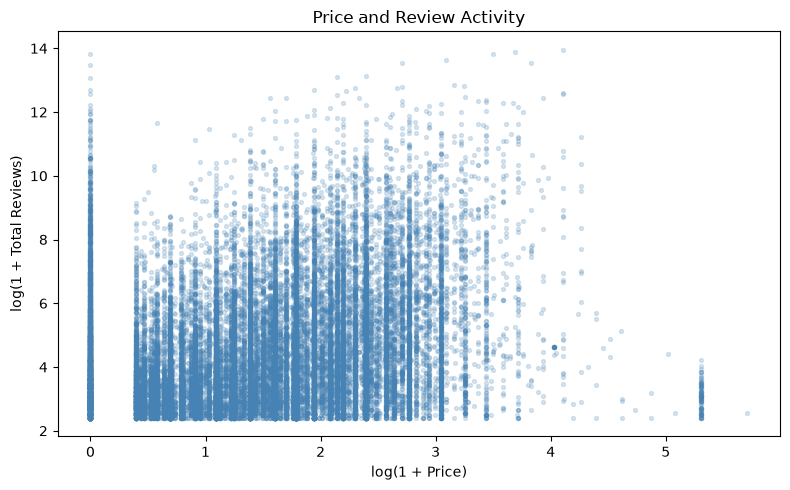

In [72]:
plt.figure(figsize=(8, 5))

plt.scatter(
    np.log1p(study["Price"]),
    np.log1p(study["Total reviews"]),
    s=8,
    alpha=0.2,
    color="steelblue",
)

plt.title("Price and Review Activity")
plt.xlabel("log(1 + Price)")
plt.ylabel("log(1 + Total Reviews)")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "price_and_review_activity.png", dpi=150)
plt.show()

### Key points
Review counts vary widely at similar prices. Zero-priced games also span a wide range of review activity. Price alone does not explain these differences.

### Correlation with Review Activity

Compare associations between game attributes and review counts.

In [73]:
from scipy import stats

columns = [
    "Average playtime forever", "Peak CCU",
    "Language count", "Price", "Release year",
]

for column in columns:
    result = stats.spearmanr(study[column], study["Total reviews"])
    print(f"{column}: {result[0]:.3f}")

Average playtime forever: 0.713
Peak CCU: 0.617
Language count: 0.323
Price: 0.235
Release year: -0.014


### Key points

Using the recorded values, average playtime has the strongest association with review counts (0.713), followed by Peak CCU (0.617). Language count and price show weaker positive associations, while release year has little association. Many activity values are zero, so the comparison below checks how the results change when those values are excluded. These correlations do not establish causation.


### Activity Values Above Zero

Compare correlations with and without recorded zeros. Each comparison uses its own subset; the main study data remains unchanged.


In [74]:
comparison_rows = []

for column in ["Average playtime forever", "Peak CCU"]:
    all_result = stats.spearmanr(study[column], study["Total reviews"])

    # Positive-only subsets are a comparison, not a correction of missing data.
    positive_values = study.loc[study[column] > 0]
    if (len(positive_values) > 1
        and positive_values[column].nunique() > 1
        and positive_values["Total reviews"].nunique() > 1):
        positive_result = stats.spearmanr(
            positive_values[column], positive_values["Total reviews"]
        )
        positive_correlation = positive_result[0]
    else:
        positive_correlation = float("nan")

    comparison_rows.append({
        "Feature": column,
        "All records": len(study),
        "All correlation": all_result[0],
        "Positive records": len(positive_values),
        "Positive correlation": positive_correlation,
    })

activity_comparison = pd.DataFrame(comparison_rows)
print(activity_comparison.round(3).to_string(index=False))


                 Feature  All records  All correlation  Positive records  Positive correlation
Average playtime forever        32387            0.713              9466                  0.50
                Peak CCU        32387            0.617             10766                  0.67


### Key points

Excluding recorded zeros changes the correlations: average playtime decreases from 0.713 to 0.500, while Peak CCU increases from 0.617 to 0.670. Both remain positively associated with review counts, but their relative strength depends on the included records. The positive-only comparisons use different subsets and do not resolve whether zeros represent missing data.

## 8. Findings and Discussion

### 1. What does the dataset represent?

| Item | Description |
|---|---|
| Selected records | 32,387 Steam games |
| Release period | 2020–2025 |
| Review threshold | At least 10 reviews |
| Data contents | Game attributes, reviews, and player activity |
| Time perspective | A dataset snapshot, not a history of changes |

### 2. Which feature appears most important?

| Feature | Spearman correlation with review counts |
|---|---:|
| Average playtime | 0.713 |
| Peak CCU | 0.617 |
| Language count | 0.323 |
| Price | 0.235 |
| Release year | -0.014 |

**Average playtime** has the strongest association when all recorded values are included. However, excluding zeros changes the ranking. Both playtime and CCU are associated with review activity, but these results do not establish a single most important feature or a causal effect.

### 3. What data quality problems were identified?

- **Header mismatch:** Discount and DLC count were merged into one header.
- **Missing values:** Some games lacked genre or category information.
- **Inconsistent text:** Language lists contained irregular quotation marks.
- **Ambiguous zeros:** Many playtime and CCU values were zero; the dataset does not distinguish all unavailable values from genuine zeros.

Review counts were also strongly skewed. This is a distribution characteristic, not necessarily a data error.

### 4. How were these problems addressed?

| Issue or analysis need | Action |
|---|---|
| Incorrect header | Separate the merged column names during loading |
| Language text | Parse using string operations |
| Genre and category text | Split into lists; represent missing entries as empty lists |
| Study scope | Filter by release period and review count |
| Ambiguous activity zeros | Retain the original values and compare correlations using positive values separately |
| Wide numerical ranges | Use log transformations in plots |
| Extreme values in summaries | Report medians alongside means |

Empty lists indicate unavailable information; they do not confirm that a game has no genres or categories.

### 5. What did you learn from the research paper?

- Define clearly what “popularity” measures.
- Prepare features according to their meaning and distribution.
- Consider uncertainty when interpreting results.

The paper predicts second-month player activity using first-month activity and game attributes. This project uses a different dataset and explores review activity, so its results are not a reproduction of the paper's predictions.

### 6. What programming techniques were applied?

| Tool or technique | Application |
|---|---|
| Pandas | Loading, selection, filtering, grouping, and aggregation |
| Functions and loops | Reusable text processing |
| String methods and lists | Parsing languages, genres, and categories |
| NumPy | Log transformations |
| Matplotlib | Creating and saving charts |
| Spearman correlation | Comparing numerical associations |